# 02 Diagnostic des masques

Questions traitées :
- le décalage vu sur Dataset Ninja existe-t-il dans les fichiers originaux ? (question 5)
- quelle est l'ampleur des défauts par espèce : décalage, coupures entre segments, remplissage ? (question 6)
- le décalage est-il constant par tube ou par session, donc corrigeable par un recalage global ? (question 7)

Les indicateurs sont calculés par `src/prmi/diagnostic.py` sur un échantillon de sessions (jusqu'à 40 sessions tube et date par sous-dossier, 10 images avec racine par session, soit 2 925 images), mis en cache dans `data/interim/mask_diagnostic.parquet` (`PYTHONPATH=src python -m prmi.diagnostic`, environ 1 min).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from prmi import viz
from prmi.diagnostic import load_diagnostic, load_pair, overlay_mask, summarize
from prmi.inventory import load_inventory

viz.apply_style()
pd.set_option('display.width', 180)
# Affichage léger dans le notebook ; les figures enregistrées sont à 150 dpi (JPEG pour les photos).
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 60

inv = load_inventory()
d = load_diagnostic()
print(d.shape)

(2925, 35)


## 1. Superpositions sur les fichiers originaux

Masque en bleu semi-transparent sur l'image d'origine, deux images avec racine par sous-dossier (part de racine supérieure à 1 %), tirées au hasard.

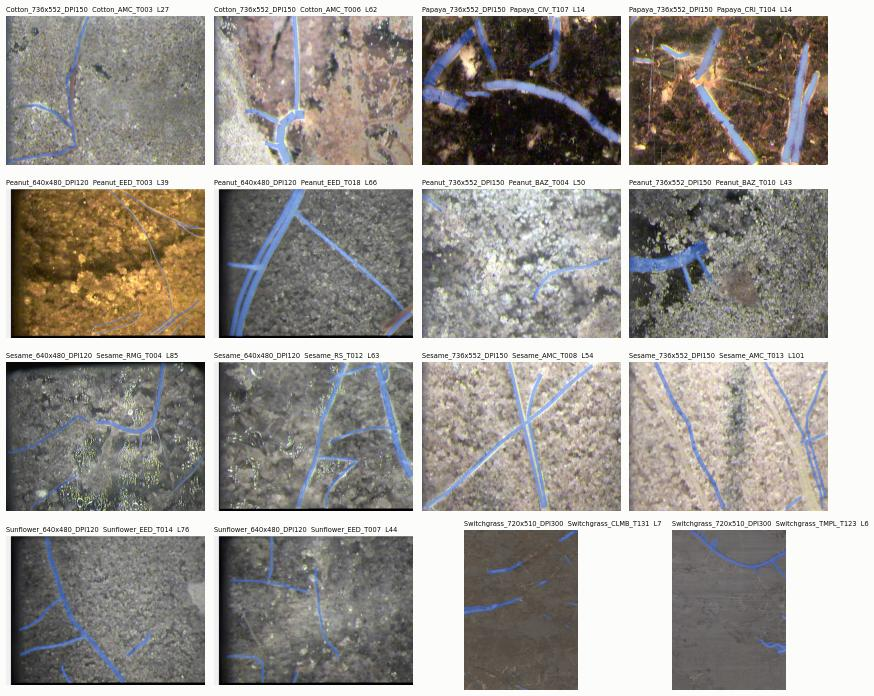

In [2]:
ex = (inv[inv['has_root'] & inv['mask_present'] & (inv['root_frac'] > 0.01)]
      .groupby('folder').sample(2, random_state=3))
imgs, titles = [], []
for _, row in ex.iterrows():
    img, m = load_pair(row)
    imgs.append(overlay_mask(img, m))
    titles.append(f"{row['folder']}  {row['tube_id']}  L{row['position']}")
fig = viz.image_grid(imgs, titles, ncols=4, width=14)
viz.save(fig, '02_grille_especes.jpg')

Ce que montrent ces grilles et les dizaines d'autres regardées pendant l'exploration :

- **le décalage existe dans les fichiers originaux** : il ne vient pas de la conversion Dataset Ninja. Il est flagrant sur le sésame 150 DPI (site AMC, 2014), où le masque longe la racine à plusieurs dizaines de pixels ;
- le tracé est une **chaîne de rectangles pleins** (WinRHIZO Tron), avec de fines fentes en coin entre segments ;
- des **racines visibles ne sont pas annotées** (coton, papaye, tournesol) et quelques masques sont posés là où aucune racine n'est visible. Ce défaut n'est pas quantifié ici : il faudrait un détecteur de racines.

## 2. Indicateurs par image

- **Décalage** : le masque est translaté de -60 à +60 px dans les deux directions ; on retient la translation qui maximise le contraste local moyen sous le masque (image moins son fond flouté). Le *gain* est le score à cette translation moins le score sans translation. Les racines sont supposées plus claires que le sol, sauf si le masque d'origine repose sur une structure nettement sombre. Estimation jugée *fiable* si le squelette du masque fait au moins 150 px et si l'optimum n'est pas sur le bord de la fenêtre.
- **Coupures** : nombre de composantes connexes reliées par une fermeture de rayon 2 px (fentes entre rectangles successifs).
- **Petits trous** : pixels non remplis entièrement entourés par le masque (trous de moins de 50 px).
- **Débord** : contraste moyen dans un anneau de 3 px autour du masque recalé, rapporté au contraste à l'intérieur. Proche de 0 : le masque couvre toute la largeur de la racine. Élevé : la racine continue hors du masque (masque trop étroit). Calculé sur les images bien alignées (décalage d'au plus 3 px).

In [3]:
summarize(d).round(3)

,images,fiables,décalage net,décalage possible,"amplitude médiane (net, px)",masques avec coupure,petits trous (% surface),débord (alignés)
folder,,,,,,,,
Cotton_736x552_DPI150,359,0.891,0.062,0.219,19.611,0.187,0.064,0.476
Papaya_736x552_DPI150,327,0.985,0.000,0.003,NaN,0.483,0.125,-0.099
Peanut_640x480_DPI120,398,0.910,0.006,0.028,54.325,0.538,0.293,0.060
Peanut_736x552_DPI150,400,0.875,0.009,0.063,30.083,0.450,0.201,0.100
Sesame_640x480_DPI120,284,0.954,0.044,0.114,22.322,0.577,0.209,0.349
Sesame_736x552_DPI150,400,0.892,0.221,0.370,47.127,0.438,0.121,0.371
Sunflower_640x480_DPI120,366,0.899,0.009,0.070,48.094,0.456,0.280,0.241
Switchgrass_720x510_DPI300,391,0.752,0.000,0.007,NaN,0.468,0.000,0.028


### Validation du décalage à l'œil

L'estimateur a été contrôlé visuellement sur 18 images tirées au hasard parmi les décalages « possibles » (gain au moins 1) et 6 images classées alignées. Résultat :

| Classement | Juste | Faux | Indécidable |
|---|---|---|---|
| décalé (18) | 5 | 6 | 7 |
| aligné (6) | 6 | 0 | 0 |

Les 6 erreurs ont toutes un gain d'au plus 2,0 (surtout des racines sombres que l'estimateur fuit vers une bande claire voisine) ; les 5 recalages justes ont tous un gain d'au moins 2,4. D'où deux niveaux :
- **décalage net** (gain au moins 2,5) : borne basse, aucune erreur vue ;
- **décalage possible** (gain au moins 1) : borne haute, environ une fausse alerte sur deux.

Le seuil est calé sur 18 images : les taux sont à lire comme des ordres de grandeur. La cellule suivante régénère la planche de contrôle (à gauche : masque d'origine, à droite : masque recalé).

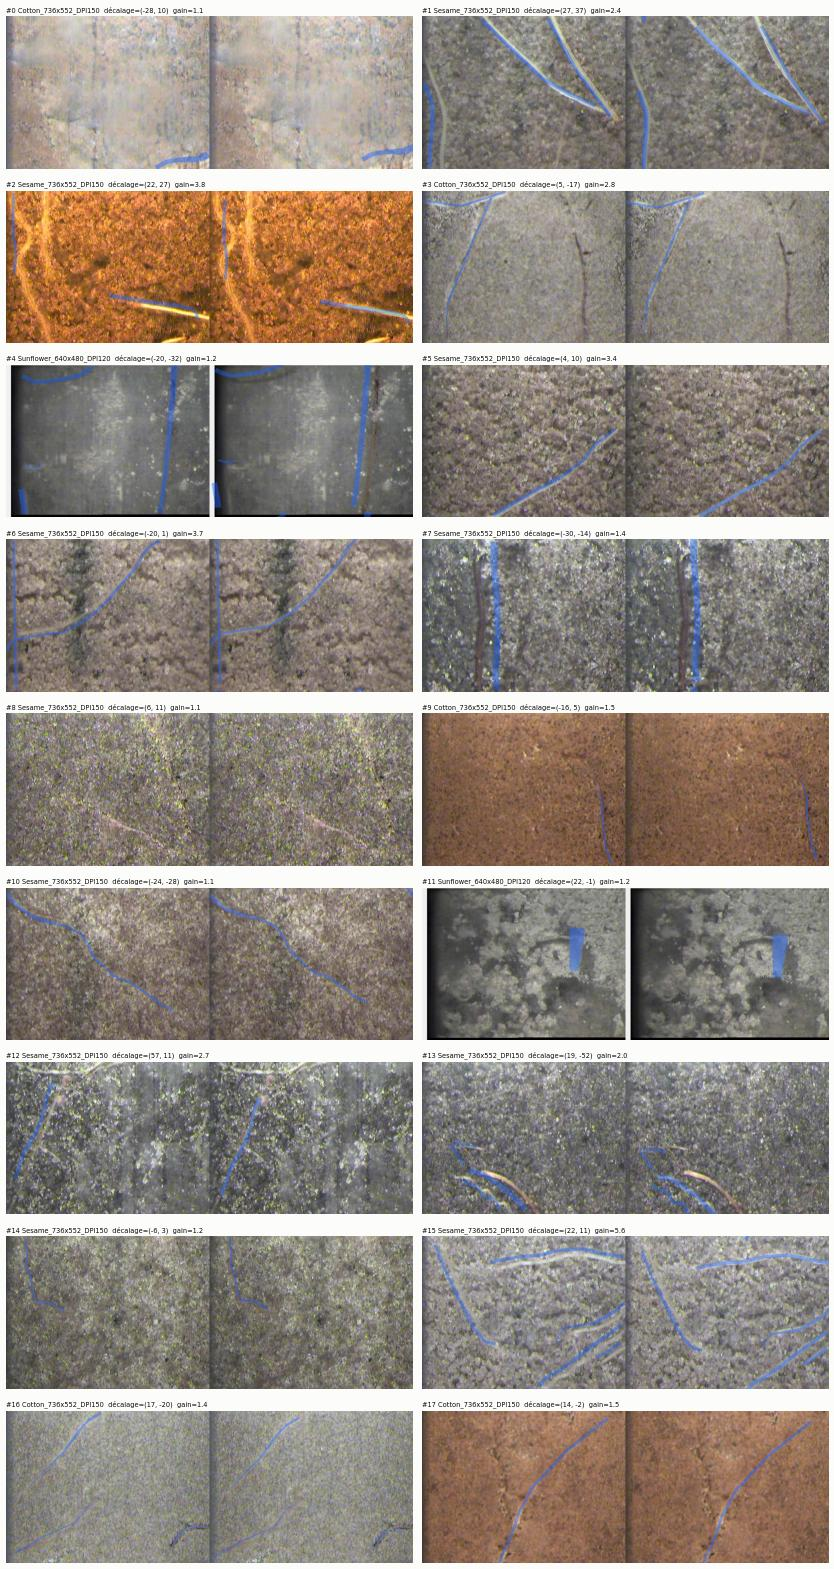

In [4]:
check = d[d['offset_possible']].sample(18, random_state=11)
imgs, titles = [], []
for k, (_, row) in enumerate(check.iterrows()):
    img, m = load_pair(row)
    shift = (int(row['dy']), int(row['dx']))
    imgs.append(np.hstack([overlay_mask(img, m), overlay_mask(img, m, shift=shift)]))
    titles.append(f"#{k} {row['folder']}  décalage={shift}  gain={row['gain']:.1f}")
fig = viz.image_grid(imgs, titles, ncols=2, width=14)

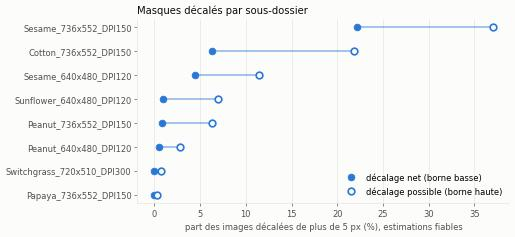

In [5]:
s = summarize(d).sort_values('décalage possible')
y = np.arange(len(s))
fig, ax = plt.subplots(figsize=(8, 4))
ax.hlines(y, 100 * s['décalage net'], 100 * s['décalage possible'], color=viz.ACCENT, linewidth=2, alpha=0.5)
ax.plot(100 * s['décalage net'], y, 'o', color=viz.ACCENT, markersize=8, label='décalage net (borne basse)')
ax.plot(100 * s['décalage possible'], y, 'o', markerfacecolor=viz.SURFACE, markeredgecolor=viz.ACCENT,
        markeredgewidth=2, markersize=8, label='décalage possible (borne haute)')
ax.set_yticks(y, s.index)
ax.set_xlabel("part des images décalées de plus de 5 px (%), estimations fiables")
ax.set_title('Masques décalés par sous-dossier', loc='left')
ax.grid(axis='y', visible=False)
ax.legend(frameon=False, loc='lower right')
viz.save(fig, '02_taux_decalage.png')

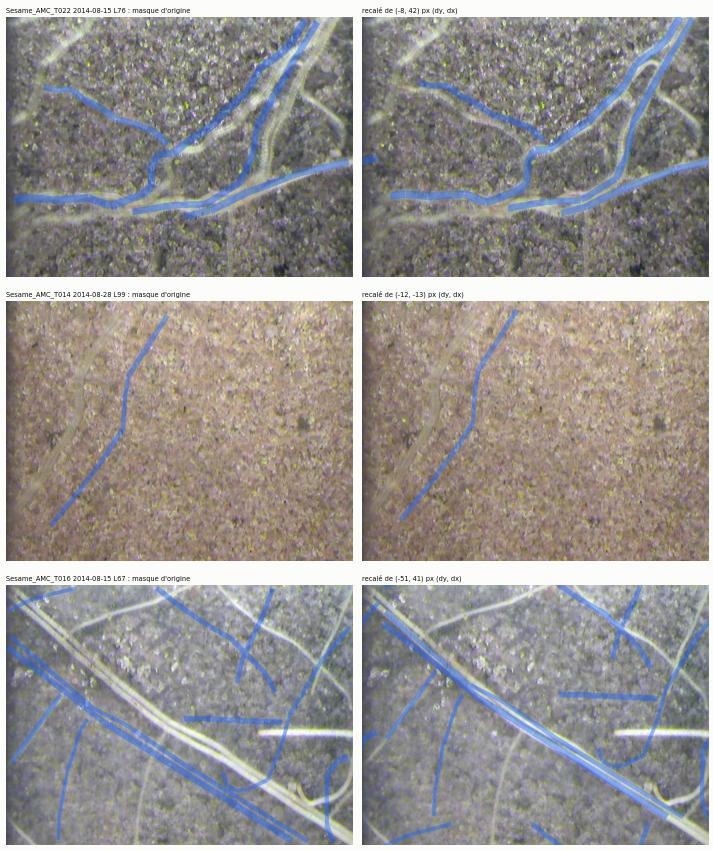

In [6]:
# Exemples de recalage sur le sésame 150 DPI (décalages nets)
ex = d[d['offset_net'] & (d['folder'] == 'Sesame_736x552_DPI150')].sample(3, random_state=4)
imgs, titles = [], []
for _, row in ex.iterrows():
    img, m = load_pair(row)
    shift = (int(row['dy']), int(row['dx']))
    imgs += [overlay_mask(img, m), overlay_mask(img, m, shift=shift)]
    titles += [f"{row['tube_id']} {row['date']:%Y-%m-%d} L{row['position']} : masque d'origine",
               f"recalé de {shift} px (dy, dx)"]
fig = viz.image_grid(imgs, titles, ncols=2, width=12)
viz.save(fig, '02_decalage_exemples.jpg')

## 3. Le décalage est-il constant par tube ou par session ?

In [7]:
# Par site et campagne : le décalage est concentré sur une campagne
r = d[d['reliable']].assign(year=lambda x: x['date'].dt.year)
(r[r['species'].isin(['Sesame', 'Cotton', 'Peanut'])]
 .groupby(['folder', 'site', 'year'])
 .agg(images=('offset_net', 'size'), tubes=('tube_id', 'nunique'), decalage_net=('offset_net', 'mean'))
 .round(2))

images  tubes  decalage_net
folder                site year                             
Cotton_736x552_DPI150 AMC  2012     320     12          0.06
Peanut_640x480_DPI120 EED  2017     362     23          0.01
Peanut_736x552_DPI150 BAZ  2015     109     11          0.01
                           2016     216     15          0.01
                      CZ   2016      25      3          0.00
Sesame_640x480_DPI120 JM   2018      10      1          0.00
                      NJ   2018      30      4          0.00
                      RMG  2019     117      4          0.05
                           2020      19      1          0.00
                      RS   2018      56      6          0.00
                           2019      39      2          0.15
Sesame_736x552_DPI150 AMC  2014     299     18          0.26
                      BCC  2012      58      6          0.00

In [8]:
# Dans une session (tube, date) qui contient des images décalées, quelle part l'est, et de combien ?
keys = ['folder', 'tube_id', 'date']
sess = r.groupby(keys).agg(images=('offset_net', 'size'), decalees=('offset_net', 'sum'))
sess = sess[sess['decalees'] > 0]
print('part des images décalées dans ces sessions (médiane par sous-dossier) :')
print((sess['decalees'] / sess['images']).groupby('folder').median().round(2))
net = r[r['offset_net']]
net.groupby(keys).agg(n=('dy', 'size'), dy_med=('dy', 'median'), dx_med=('dx', 'median'),
                      dy_sd=('dy', 'std'), dx_sd=('dx', 'std')).query('n >= 3').round(1)

part des images décalées dans ces sessions (médiane par sous-dossier) :
folder
Cotton_736x552_DPI150       0.12
Peanut_640x480_DPI120       0.11
Peanut_736x552_DPI150       0.10
Sesame_640x480_DPI120       0.20
Sesame_736x552_DPI150       0.25
Sunflower_640x480_DPI120    0.18
dtype: float64


n  dy_med  dx_med  dy_sd  dx_sd
folder                tube_id         date                                       
Sesame_736x552_DPI150 Sesame_AMC_T007 2014-08-28  6    22.0    34.5   27.5   37.5
                      Sesame_AMC_T008 2014-09-11  5    24.0   -40.0   19.7   20.0
                      Sesame_AMC_T014 2014-08-28  6   -22.0   -43.5   21.8   15.2
                      Sesame_AMC_T015 2014-08-28  7   -20.0   -10.0   36.0   21.6
                      Sesame_AMC_T018 2014-07-11  3    11.0    23.0   12.0   30.1
                                      2014-08-15  4    -3.5   -18.5   30.6   13.9
                                      2014-08-28  5     5.0    29.0   22.5   14.6
                      Sesame_AMC_T019 2014-08-15  3     4.0    10.0   49.4   16.2
                                      2014-08-28  8    27.0    26.5   30.9   31.7
                      Sesame_AMC_T020 2014-09-11  5    21.0    24.0   26.6   44.3
                      Sesame_AMC_T022 2014-08-15  6     8.5    48.0   27.7   19.4

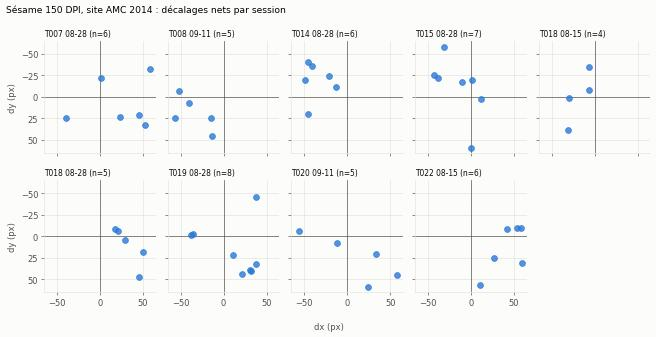

In [9]:
# Petits multiples : décalages nets des sessions de sésame 150 DPI qui en ont au moins 4
ses = net[net['folder'] == 'Sesame_736x552_DPI150']
groups = [(k, g) for k, g in ses.groupby(['tube_id', 'date']) if len(g) >= 4]
ncols = 5
nrows = -(-len(groups) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(11, 2.5 * nrows + 0.6), sharex=True, sharey=True, squeeze=False)
for ax in axes.flat[len(groups):]:
    ax.axis('off')
for ax, ((tube, date), g) in zip(axes.flat, groups):
    ax.axhline(0, color=viz.INK_2, linewidth=0.8)
    ax.axvline(0, color=viz.INK_2, linewidth=0.8)
    ax.plot(g['dx'], g['dy'], 'o', color=viz.ACCENT, markersize=7, alpha=0.8)
    ax.set_title(f"{tube.split('_')[-1]} {date:%m-%d} (n={len(g)})", fontsize=9, loc='left')
    ax.set_xlim(-65, 65)
    ax.set_ylim(65, -65)
    ax.set_aspect('equal')
for ax in axes[:, 0]:
    ax.set_ylabel('dy (px)')
fig.supxlabel('dx (px)', fontsize=10, color=viz.INK_2)
fig.suptitle('Sésame 150 DPI, site AMC 2014 : décalages nets par session', x=0.01, ha='left', fontsize=11)
fig.tight_layout()
viz.save(fig, '02_constance_session.png')

Le décalage **n'est pas constant** : dans une même session, seule une partie des images est décalée (un quart à un tiers en médiane pour le sésame 150 DPI) et les décalages vont dans des directions différentes, avec des écarts-types de 15 à 45 px. Un recalage global par tube ou par session ne suffira pas : il faudra un recalage **par image**. Sur les exemples regardés, une seule translation remet toutes les racines d'une image en place (troisième exemple ci-dessus) : le décalage semble constant à l'échelle de l'image, ce qui reste à vérifier plus largement. Le critère d'alignement devra être plus robuste que celui-ci pour les racines sombres.

## 4. Coupures et remplissage

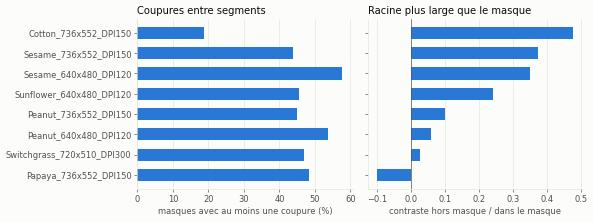

In [10]:
s = summarize(d)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
order = s['débord (alignés)'].sort_values().index
axes[0].barh(order, 100 * s.loc[order, 'masques avec coupure'], color=viz.ACCENT, height=0.6)
axes[0].set_xlabel('masques avec au moins une coupure (%)')
axes[0].set_title('Coupures entre segments', loc='left')
axes[1].barh(order, s.loc[order, 'débord (alignés)'], color=viz.ACCENT, height=0.6)
axes[1].axvline(0, color=viz.INK_2, linewidth=0.8)
axes[1].set_xlabel('contraste hors masque / dans le masque')
axes[1].set_title('Racine plus large que le masque', loc='left')
for ax in axes:
    ax.grid(axis='y', visible=False)
fig.tight_layout()
viz.save(fig, '02_coupures_debord.png')

- **Coupures** : environ la moitié des masques en ont au moins une (19 % pour le coton). Ce sont des fentes de 1 à 2 px entre rectangles : faciles à combler par une fermeture, mais elles coupent le squelette et faussent la longueur si on ne les traite pas.
- **Petits trous** : négligeables (0,1 à 0,3 % de la surface du masque).
- **Remplissage incomplet** : sur des images bien alignées, le contraste se prolonge hors du masque pour le coton, le sésame et le tournesol (rapport de 0,24 à 0,48) : les rectangles sont plus étroits que les racines, ce qui biaisera le diamètre. L'arachide et le switchgrass couvrent bien la largeur (0,03 à 0,10). Limite : les poils absorbants du sésame peuvent aussi gonfler cet indicateur.

## À retenir

- Le décalage est réel dans les fichiers originaux, concentré sur le sésame 150 DPI du site AMC en 2014 (22 à 37 % des images, amplitude médiane 47 px) et, dans une moindre mesure, le coton (6 à 22 %).
- Il varie d'une image à l'autre dans une même session : pas de recalage global possible.
- L'arachide (120 et 150 DPI), le tournesol, la papaye et le switchgrass sont peu ou pas décalés (au plus 1 % net, 7 % possible).
- Coupures fréquentes partout, petits trous négligeables, masques trop étroits pour le coton, le sésame et le tournesol.
- Non quantifié : racines visibles non annotées.